# 03_Text_Exploration — Train Set Only

In [1]:
import os
if 'notebooks' in os.getcwd():
    os.chdir('..')
os.makedirs('output', exist_ok=True)
print(f'Working directory: {os.getcwd()}')

Working directory: D:\Data analyst\Portfolio\Banque\bank-complaint-routing-nlp


In [2]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.width', 200)
print('✓ Libraries loaded')

✓ Libraries loaded


In [3]:
import hashlib, re
from collections import Counter
import yaml
cfg = yaml.safe_load(open('config/config.yaml', encoding='utf-8'))
man = json.load(open('data/processed/MANIFEST.json', encoding='utf-8'))
h = hashlib.sha256()
with open('data/processed/train.parquet', 'rb') as f:
    for b in iter(lambda: f.read(8 * 1024**2), b''):
        h.update(b)
assert h.hexdigest() == man['train']['sha256'], 'train.parquet modified since Phase 2b'
train = pd.read_parquet('data/processed/train.parquet')
assert set(train['split']) == {'train'}
SERVICES = sorted(train['service'].unique())
print(f'✓ Loaded train: {train.shape} (sha256 OK)')

✓ Loaded train: (74415, 12) (sha256 OK)


## 1. Distribution & Length by Service

                              n  median_words  share_pct
service                                                 
Recouvrement              22084         154.0      29.68
Monétique                 15169         206.0      20.38
Comptes & Dépôts          14906         188.0      20.03
Crédits aux particuliers   9987         200.0      13.42
Transferts & Paiements     6831         186.0       9.18
Crédit immobilier          5438         248.0       7.31


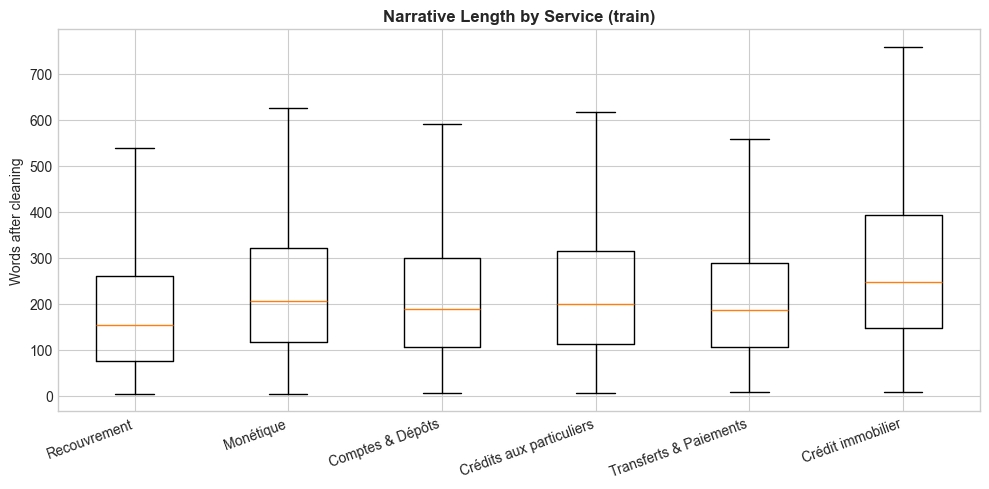

✓ Saved: 03_length_by_service.png


In [4]:
dist = train.groupby('service').agg(n=('complaint_id', 'size'), median_words=('n_words_clean', 'median'))
dist['share_pct'] = (100 * dist['n'] / dist['n'].sum()).round(2)
dist = dist.sort_values('n', ascending=False)
print(dist.to_string())
order = dist.index.tolist()
fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot([train.loc[train['service'] == s, 'n_words_clean'] for s in order], showfliers=False)
ax.set_xticks(range(1, len(order) + 1), order, rotation=20, ha='right')
ax.set_title('Narrative Length by Service (train)', fontsize=12, fontweight='bold')
ax.set_ylabel('Words after cleaning')
plt.tight_layout()
plt.savefig('output/03_length_by_service.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 03_length_by_service.png')

## 2. Mask Tokens by Service

% of narratives containing the token:
                          [DATE]  [AMOUNT]  [REDACTED]
Recouvrement               38.15     33.46       78.29
Monétique                  58.88     54.47       85.77
Comptes & Dépôts           58.41     54.15       83.21
Crédits aux particuliers   55.27     42.16       82.68
Transferts & Paiements     59.52     58.44       85.27
Crédit immobilier          67.01     44.83       87.72


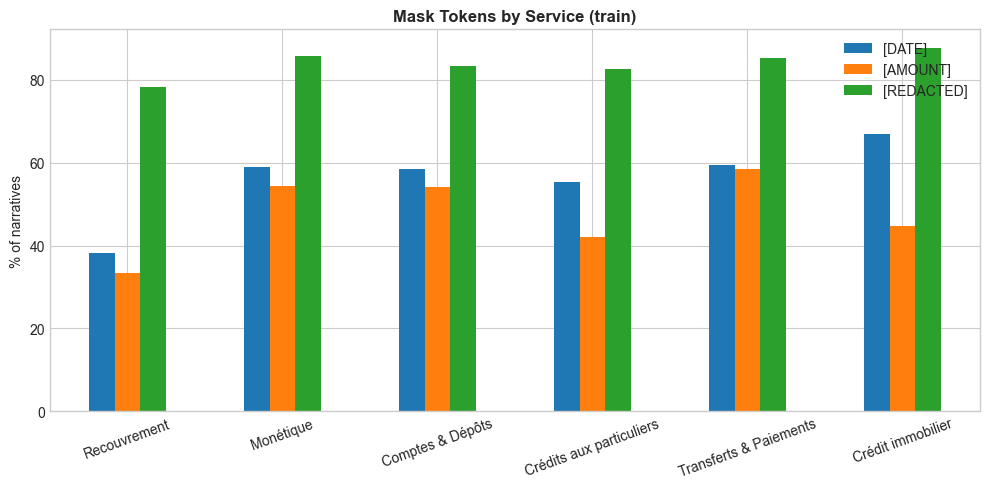

✓ Saved: 03_mask_tokens_by_service.png


In [5]:
tokens = [cfg['phase2']['mask_tokens']['date'], cfg['phase2']['amount_token'], cfg['phase2']['mask_tokens']['generic']]
tok = pd.DataFrame({t: [100 * (train.loc[train['service'] == s, 'text_clean'].str.count(re.escape(t)) > 0).mean()
                        for s in order] for t in tokens}, index=order).round(2)
print('% of narratives containing the token:'); print(tok.to_string())
ax = tok.plot.bar(figsize=(10, 5), rot=20)
ax.set_title('Mask Tokens by Service (train)', fontsize=12, fontweight='bold'); ax.set_ylabel('% of narratives')
plt.tight_layout()
plt.savefig('output/03_mask_tokens_by_service.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 03_mask_tokens_by_service.png')

## 3. Discriminant Vocabulary (log-odds, informative Dirichlet prior)

In [6]:
STOP = set(('the a an and or but to of in on at for with from by is was were are be been have has had i my me '
            'you your it this that they them their not no do did does as so if we our he she his her '
            'would could should will can there what when which who all any also about after into than then '
            'out up just only been being because over more very am').split())
WORD_RE = re.compile(r'\[(?:redacted|date|amount)\]|[a-z]+(?:\'[a-z]+)?')
def toks(t):
    return [w for w in WORD_RE.findall(t.lower()) if w not in STOP and (w.startswith('[') or len(w) > 2)]
docs = train['text_clean'].map(toks)
by_s = {s: Counter() for s in SERVICES}
for s, d in zip(train['service'], docs):
    by_s[s].update(d)
total = Counter()
for c in by_s.values():
    total.update(c)
vocab = [w for w, n in total.items() if n >= 50]
counts = pd.DataFrame({s: [by_s[s].get(w, 0) for w in vocab] for s in SERVICES}, index=vocab)
alpha = counts.sum(axis=1).astype(float); a0 = alpha.sum()
def z(i):
    yi = counts[i]; yj = counts.drop(columns=i).sum(axis=1); ni, nj = yi.sum(), yj.sum()
    d = np.log((yi + alpha) / (ni + a0 - yi - alpha)) - np.log((yj + alpha) / (nj + a0 - yj - alpha))
    return d / np.sqrt(1 / (yi + alpha) + 1 / (yj + alpha))
Z = pd.DataFrame({s: z(s) for s in SERVICES})
top = pd.DataFrame({s: pd.Series(Z[s].nlargest(15).index.tolist(), dtype=object) for s in SERVICES})
top.index = top.index + 1
print(f'Vocabulary kept: {len(vocab):,} words'); print(top.to_string())

Vocabulary kept: 6,399 words
   Comptes & Dépôts Crédit immobilier Crédits aux particuliers  Monétique Recouvrement Transferts & Paiements
1              bank          mortgage                     loan       card         debt                 paypal
2             funds            escrow                  vehicle  synchrony   collection                    app
3             check       foreclosure                    loans   merchant   validation                   cash
4      transactions         servicing                   mohela       citi    reporting                  funds
5          checking              loan                  student    express      alleged                  money
6            branch      modification             repossession     charge      collect            transaction
7           deposit          servicer                      car   american        fdcpa               transfer
8             chime          property                repayment     credit       credit     

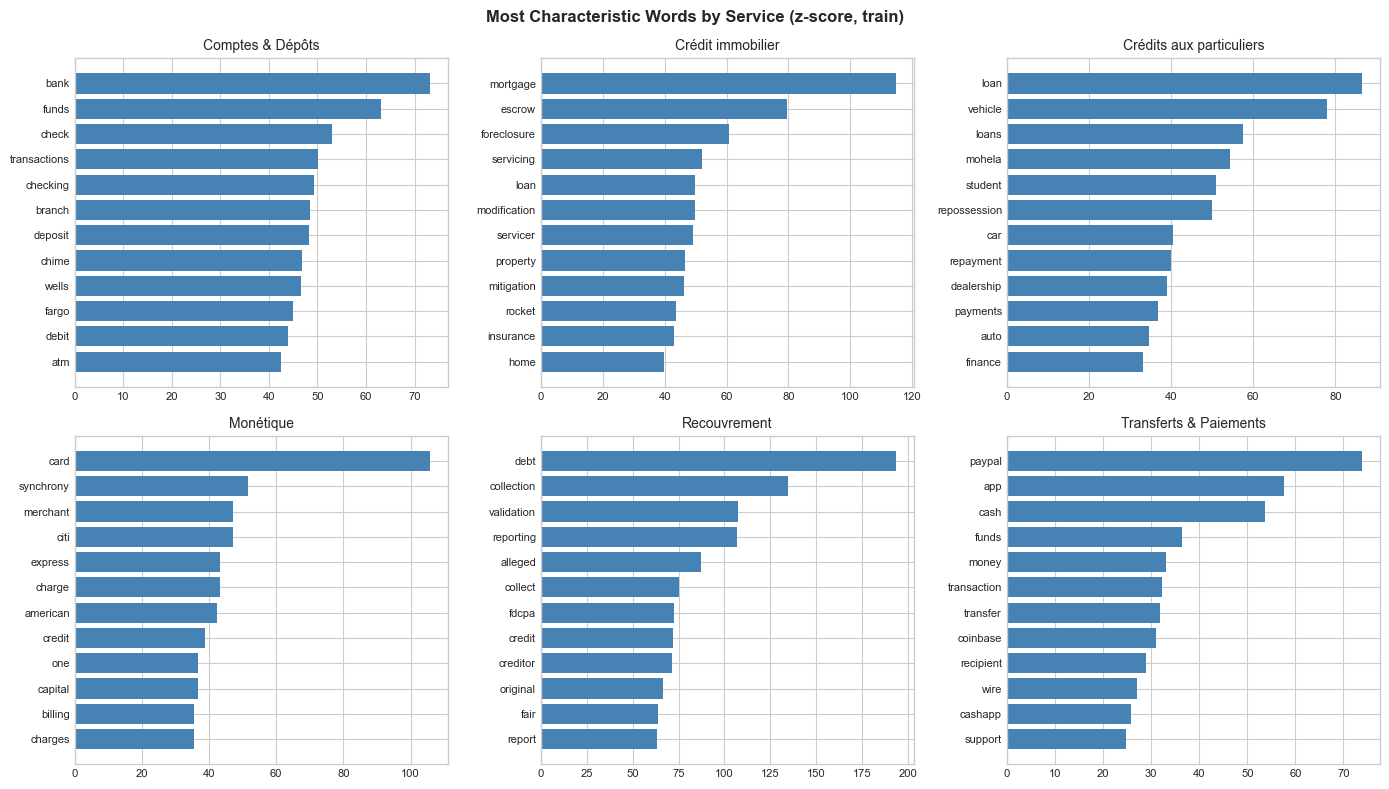

✓ Saved: 03_discriminant_words.png


In [7]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, s in zip(axes.ravel(), SERVICES):
    t = Z[s].nlargest(12)[::-1]
    ax.barh(t.index, t.values, color='steelblue'); ax.set_title(s, fontsize=10); ax.tick_params(labelsize=8)
fig.suptitle('Most Characteristic Words by Service (z-score, train)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('output/03_discriminant_words.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 03_discriminant_words.png')

## 4. Top Bigrams by Service

In [8]:
big = {s: Counter() for s in SERVICES}
for s, d in zip(train['service'], docs):
    big[s].update(f'{a} {b}' for a, b in zip(d, d[1:]) if not (a.startswith('[') and b.startswith('[')))
for s in SERVICES:
    print(f'\n=== {s} ===')
    for b, n in big[s].most_common(10):
        print(f'  {b:<35} {n:>7,}')


=== Comptes & Dépôts ===
  wells fargo                           6,662
  checking account                      4,004
  bank america                          3,771
  debit card                            3,607
  customer service                      2,402
  [redacted] account                    2,226
  capital one                           2,197
  account [redacted]                    2,077
  provisional credit                    2,031
  cash app                              1,974

=== Crédit immobilier ===
  loss mitigation                       2,188
  rocket mortgage                       1,494
  loan modification                     1,249
  escrow account                        1,177
  mortgage payment                      1,078
  credit reporting                        897
  wells fargo                             880
  approximately [amount]                  852
  freedom mortgage                        840
  mortgage servicing                      795

=== Crédits aux particulie

  credit reporting                      2,496
  student loan                          1,605
  complaint regarding                   1,400
  approximately [amount]                1,295
  credit report                         1,254
  federal student                       1,242
  filing complaint                      1,169
  auto loan                             1,130
  payment history                       1,121
  student loans                           989

=== Monétique ===
  credit card                          11,327
  capital one                           5,955
  american express                      3,259
  customer service                      3,154
  bank america                          3,145
  wells fargo                           2,811
  card account                          2,148
  credit reporting                      2,059
  synchrony bank                        1,995
  complaint regarding                   1,944

=== Recouvrement ===
  credit reporting                     